# Pressure differences and balanced flow

Can a flow point opposite its diagram arrow and still satisfy conservation?

Fall 2024.


## Predict
Which way should the bridge flow when A is at 42 mmHg and B is at 60 mmHg? Record a signed A-to-B prediction before running.

{'source': 96.0, 'sink': 6.0, 'A': 42.0, 'B': 60.00000000000001}
[2.7, 3.6, 3.599999999999999, 2.7, -0.9000000000000004]


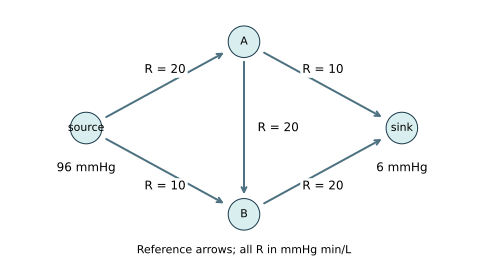

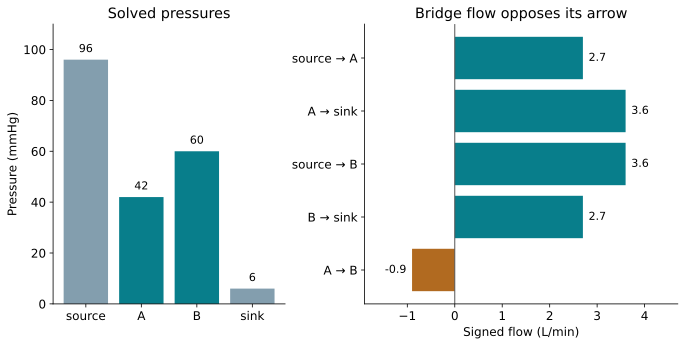

In [1]:
import demo
from IPython.display import display, SVG
report = demo.run()
print(report['pressure_mmHg'])
print(report['flow_L_min'])
display(SVG(filename='network.svg'))
display(SVG(filename='pressures-and-flows.svg'))

## Interpret
Check both internal balances by hand. Explain why the bridge reference value is negative and why clipping it would change the model.

In [2]:
baseline = demo.solve_network()
shifted = demo.solve_network(source=108, sink=18)
print('Original:', baseline['flow_L_min'])
print('Shifted reference:', shifted['flow_L_min'])

Original: [ 2.7  3.6  3.6  2.7 -0.9]
Shifted reference: [ 2.7  3.6  3.6  2.7 -0.9]


## Modify
Double only the source-to-A resistance. Predict whether A becomes closer in pressure to the source or sink, then run. Check both balances even if your direction prediction was wrong.

In [3]:
r = demo.DEFAULT_R.copy()
r[0] *= 2
trial = demo.solve_network(resistances=r)
print(trial['pressure_mmHg'])
print(trial['flow_L_min'])
print('Internal net outflows:', {k: trial['net_out_L_min'][k] for k in ('A','B')})

{'source': 96.0, 'sink': 6.0, 'A': 33.6923076923077, 'B': 57.923076923076934}
[ 1.55769231  2.76923077  3.80769231  2.59615385 -1.21153846]
Internal net outflows: {'A': np.float64(8.881784197001252e-16), 'B': np.float64(1.7763568394002505e-15)}


## Explain
Which part of the calculation verifies its implementation? What additional measurements would test whether the model describes a real system? The network and numerical inputs are synthetic.